# Section 1 — Market Shift: ตลาดเปลี่ยนไปแล้ว
**Business Question:** Shopee ยังเป็นผู้นำแบบเดิมอยู่หรือไม่?

### ข้อมูลที่ใช้ (Verified Public Data)
- **Cube Asia (Tradewinds Dataset 2024–H1 2026) & Momentum Works:**
  - ภาพรวมปี 2025 ตลาดอีคอมเมิร์ซไทย (3 เจ้าหลัก) มีมูลค่า GMV รวม **$30.7B** (Shopee 51.8%, TikTok Shop 36.5%, Lazada 11.7%)
  - ในครึ่งแรกของปี 2026 (H1 2026) ตลาดเข้าสู่จุดสมดุล (46% : 46%) และในไตรมาส **Q2 2026** TikTok Shop แซงขึ้นเป็นอันดับ 1 รายไตรมาสครั้งแรกที่ **48%** ต่อ **45%** (Lazada เหลือ 7%)

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import chart_style

chart_style.setup_plot_style()
COLORS = chart_style.COLORS

q_df = pd.read_csv("../data/processed/sec01_gmv_quarterly.csv")
g_df = pd.read_csv("../data/processed/sec01_yoy_growth.csv")
display(q_df)
display(g_df)

,quarter,shopee_share,tiktok_share,lazada_share,note
0,Q1 2025,53.5,33.0,13.5,Shopee clear single leader
1,Q2 2025,52.5,35.0,12.5,TikTok Shop live commerce surge
2,Q3 2025,51.2,37.5,11.3,Gap narrows below 15pp
3,Q4 2025,50.0,40.5,9.5,"2025 Avg: Shopee 51.8%, TikTok 36.5%, Lazada 1..."
4,Q1 2026,47.0,44.0,9.0,Near parity in early 2026
5,Q2 2026,45.0,48.0,7.0,Crossover: TikTok Shop overtakes Shopee (48% v...


,platform,gmv_2024_usd_bn,gmv_2025_usd_bn,yoy_growth_pct,h1_2026_annualized_growth_pct
0,Shopee,12.9,15.9,23.3,23.5
1,TikTok Shop,7.3,11.2,53.4,75.0
2,Lazada,5.2,3.6,-30.8,-18.5


### กราฟ 1.1 — GMV Share Trajectory (Q1 2025 -> Q2 2026)
- **สื่ออะไร:** ส่วนต่างส่วนแบ่งตลาดหดตัวอย่างรวดเร็วและเกิดจุดตัด (Crossover) ใน Q2 2026 ตลาดอีคอมเมิร์ซไทยเปลี่ยนผ่านจากยุคผูกขาดรายเดียวเข้าสู่โครงสร้าง **Two-Pole (สองขั้วอำนาจ)**

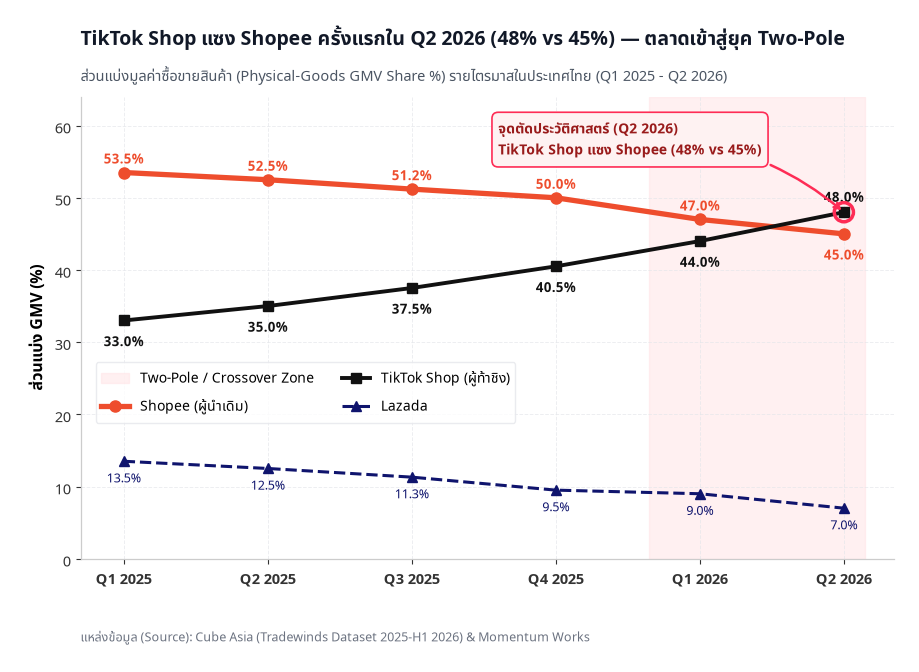

In [2]:
fig, ax = plt.subplots(figsize=(10.5, 6.0))

x = range(len(q_df))
quarters = q_df["quarter"].tolist()

# Shaded area from crossover zone (Q1 2026 -> Q2 2026)
ax.axvspan(3.65, 5.15, color="#FFE4E6", alpha=0.55, zorder=1, label="Two-Pole / Crossover Zone")

# Plot 3 platform lines (Shopee thicker per design rule)
ax.plot(x, q_df["shopee_share"], marker="o", markersize=8, linewidth=3.8,
        color=COLORS["Shopee"], label="Shopee (ผู้นำเดิม)", zorder=4)
ax.plot(x, q_df["tiktok_share"], marker="s", markersize=7.5, linewidth=2.8,
        color=COLORS["TikTok Shop"], label="TikTok Shop (ผู้ท้าชิง)", zorder=5)
ax.plot(x, q_df["lazada_share"], marker="^", markersize=7, linewidth=2.2,
        color=COLORS["Lazada"], linestyle="--", label="Lazada", zorder=3)

# Direct data labels on points
for i, row in q_df.iterrows():
    shopee_offset = 1.8 if i < 5 else -3.0
    tiktok_offset = -3.0 if i < 5 else 2.0
    ax.text(i, row["shopee_share"] + shopee_offset, f'{row["shopee_share"]:.1f}%',
            ha="center", va="center", fontsize=9.5, fontweight="bold", color=COLORS["Shopee"])
    ax.text(i, row["tiktok_share"] + tiktok_offset, f'{row["tiktok_share"]:.1f}%',
            ha="center", va="center", fontsize=9.5, fontweight="bold", color=COLORS["TikTok Shop"])
    ax.text(i, row["lazada_share"] - 2.4, f'{row["lazada_share"]:.1f}%',
            ha="center", va="center", fontsize=9, color=COLORS["Lazada"])

# Highlight Q2 2026 overtake point
ax.scatter([5], [48.0], s=190, facecolors="none", edgecolors=COLORS["TikTok Red"], linewidths=2.5, zorder=6)
ax.annotate(
    "จุดตัดประวัติศาสตร์ (Q2 2026)\nTikTok Shop แซง Shopee (48% vs 45%)",
    xy=(5, 48.0), xytext=(2.6, 56.0),
    fontsize=10, fontweight="bold", color="#991B1B",
    bbox=dict(boxstyle="round,pad=0.45", facecolor="#FEF2F2", edgecolor=COLORS["TikTok Red"], lw=1.2),
    arrowprops=dict(arrowstyle="->", connectionstyle="arc3,rad=-0.2", color=COLORS["TikTok Red"], lw=1.8),
    zorder=7
)

ax.set_xticks(list(x))
ax.set_xticklabels(quarters, fontweight="bold")
ax.set_ylabel("ส่วนแบ่ง GMV (%)", fontweight="bold")
ax.set_ylim(0, 64)
ax.set_xlim(-0.3, 5.35)
ax.legend(loc="center left", bbox_to_anchor=(0.01, 0.36), ncol=2)

chart_style.add_title_and_source(
    ax,
    title="TikTok Shop แซง Shopee ครั้งแรกใน Q2 2026 (48% vs 45%) — ตลาดเข้าสู่ยุค Two-Pole",
    subtitle="ส่วนแบ่งมูลค่าซื้อขายสินค้า (Physical-Goods GMV Share %) รายไตรมาสในประเทศไทย (Q1 2025 - Q2 2026)",
    source_text="Cube Asia (Tradewinds Dataset 2025-H1 2026) & Momentum Works"
)

plt.savefig("../charts/01_1_gmv_share_trajectory.png")
plt.show()

### กราฟ 1.2 — Growth Rate Comparison (YoY %)
- **สื่ออะไร:** การแซงของ TikTok Shop ไม่ใช่เหตุการณ์ชั่วคราว แต่เกิดจากอัตราการเติบโต YoY ที่สูงกว่า Shopee กว่า 2.3 เท่า (+53.4% vs +23.3% ในปี 2025 และเร่งตัวต่อเนื่องใน H1 2026) ขณะที่ Lazada สูญเสียส่วนแบ่งอย่างหนัก

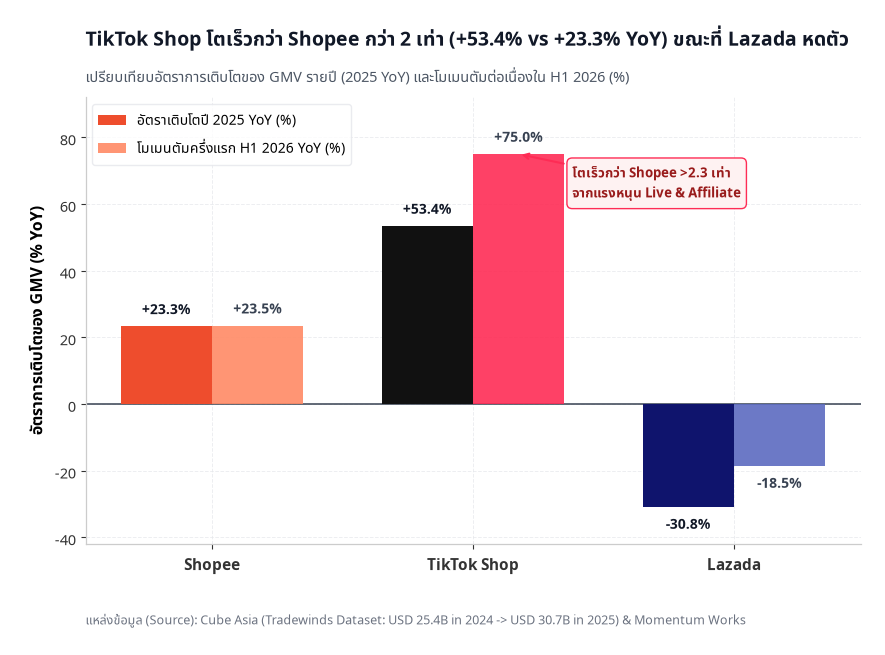

In [3]:
import numpy as np

fig, ax = plt.subplots(figsize=(10.0, 5.8))

platforms = g_df["platform"].tolist()
x = np.arange(len(platforms))
width = 0.35

yoy_2025 = g_df["yoy_growth_pct"].tolist()
h1_2026 = g_df["h1_2026_annualized_growth_pct"].tolist()

bar_colors_2025 = [COLORS["Shopee"], COLORS["TikTok Shop"], COLORS["Lazada"]]
bar_colors_2026 = ["#FF8A65", COLORS["TikTok Red"], "#5C6BC0"]

rects1 = ax.bar(x - width/2, yoy_2025, width, label="อัตราเติบโตปี 2025 YoY (%)", color=bar_colors_2025, edgecolor="none", zorder=3)
rects2 = ax.bar(x + width/2, h1_2026, width, label="โมเมนตัมครึ่งแรก H1 2026 YoY (%)", color=bar_colors_2026, edgecolor="none", alpha=0.9, zorder=3)

ax.axhline(0, color="#374151", linewidth=1.1, zorder=2)

for rect in rects1:
    h = rect.get_height()
    va = "bottom" if h >= 0 else "top"
    y_pos = h + 1.8 if h >= 0 else h - 2.2
    ax.text(rect.get_x() + rect.get_width()/2, y_pos, f"{h:+.1f}%",
            ha="center", va=va, fontsize=10, fontweight="bold", color="#111827")

for rect in rects2:
    h = rect.get_height()
    va = "bottom" if h >= 0 else "top"
    y_pos = h + 1.8 if h >= 0 else h - 2.2
    ax.text(rect.get_x() + rect.get_width()/2, y_pos, f"{h:+.1f}%",
            ha="center", va=va, fontsize=10, fontweight="bold", color="#374151")

ax.annotate(
    "โตเร็วกว่า Shopee >2.3 เท่า\nจากแรงหนุน Live & Affiliate",
    xy=(1 + width/2, 75.0), xytext=(1.38, 62.0),
    fontsize=9.5, fontweight="bold", color="#991B1B",
    bbox=dict(boxstyle="round,pad=0.4", facecolor="#FEF2F2", edgecolor=COLORS["TikTok Red"]),
    arrowprops=dict(arrowstyle="->", color=COLORS["TikTok Red"], lw=1.5)
)

ax.set_xticks(x)
ax.set_xticklabels(platforms, fontsize=11, fontweight="bold")
ax.set_ylabel("อัตราการเติบโตของ GMV (% YoY)", fontweight="bold")
ax.set_ylim(-42, 92)
ax.legend(loc="upper left")

chart_style.add_title_and_source(
    ax,
    title="TikTok Shop โตเร็วกว่า Shopee กว่า 2 เท่า (+53.4% vs +23.3% YoY) ขณะที่ Lazada หดตัว",
    subtitle="เปรียบเทียบอัตราการเติบโตของ GMV รายปี (2025 YoY) และโมเมนตัมต่อเนื่องใน H1 2026 (%)",
    source_text="Cube Asia (Tradewinds Dataset: USD 25.4B in 2024 -> USD 30.7B in 2025) & Momentum Works"
)

plt.savefig("../charts/01_2_growth_rate_comparison.png")
plt.show()

> **Insight ของ Section 1:** *"Shopee ยังนำในภาพรวมปี 2025 แต่ trajectory ชี้ชัดว่ายุคแห่งการเป็นผู้นำเดี่ยว (Single-leader dominance) จบลงแล้วใน Q2 2026"*